# Outlier Treatment

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

data = {
    'Employee_ID': range(1, 16),
    'Salary': [
        25000, 27000, 28000, 29000, 30000,
        31000, 32000, 33000, 34000, 35000,
        36000, 37000, 38000, 39000, 200000
    ]
}

df = pd.DataFrame(data)

print(df)

    Employee_ID  Salary
0             1   25000
1             2   27000
2             3   28000
3             4   29000
4             5   30000
5             6   31000
6             7   32000
7             8   33000
8             9   34000
9            10   35000
10           11   36000
11           12   37000
12           13   38000
13           14   39000
14           15  200000



## What is an Outlier?
An outlier is a data point that is significantly different from most other observations in a dataset.

### Example:
Imagine the monthly salaries of five employees:

In [3]:
import pandas as pd
import numpy as np

salary = [25000, 28000, 30000, 32000, 35000, 200000]

df = pd.DataFrame({
    'Salary': salary
})

print(df)


   Salary
0   25000
1   28000
2   30000
3   32000
4   35000
5  200000


## Outlier vs Error
An outlier and an error are not the same.
#### Outlier
- An unusually high or low value	
- May be genuine	
- Needs investigation
- May be retained	
#### Error
- An incorrect or invalid value
- Usually caused by incorrect data entry or processing
- 	Usually needs correction
- Should be corrected or handled
### Example 1 
Possible data-entry error

An employee's age is recorded as 250  

age = 250

## IQR Method (Interquartile Range)
The IQR method identifies outliers using the middle 50% of the data.

### Formula:
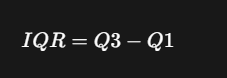

Where:
- Q1 = 25th percentile.
- Q3 = 75th percentile.
- IQR = Difference between Q3 and Q1.

In [5]:
Q1 = df['Salary'].quantile(0.25)
Q3 = df['Salary'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)

print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)
outliers_iqr = df[
    (df['Salary'] < lower_bound) |
    (df['Salary'] > upper_bound)
]

print("Outliers using IQR:")
print(outliers_iqr)

Q1: 28500.0
Q3: 34250.0
IQR: 5750.0
Lower Bound: 19875.0
Upper Bound: 42875.0
Outliers using IQR:
   Salary
5  200000


## Z-Score Method
The Z-score method measures how far a value is from the mean in terms of standard deviations.

### Formula:
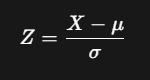

Where:
- X = Individual value.
- μ = Mean.
- σ = Standard deviation.

In [6]:
mean = df['Salary'].mean()
std = df['Salary'].std()

df['Z_Score'] = (
    df['Salary'] - mean
) / std

print(df[['Salary', 'Z_Score']])
z_outliers = df[
    df['Z_Score'].abs() > 3
]

print("Outliers using Z-Score:")
print(z_outliers)

   Salary   Z_Score
0   25000 -0.479715
1   28000 -0.436540
2   30000 -0.407758
3   32000 -0.378975
4   35000 -0.335800
5  200000  2.038788
Outliers using Z-Score:
Empty DataFrame
Columns: [Salary, Z_Score]
Index: []


## Percentile Method
The percentile method identifies unusually low or high values using percentile boundaries.

### Example:
- Values below the 1st percentile may be flagged.
- Values above the 99th percentile may be flagged.

In [7]:
lower_limit = df['Salary'].quantile(0.01)
upper_limit = df['Salary'].quantile(0.99)

print("1st Percentile:", lower_limit)
print("99th Percentile:", upper_limit)

percentile_outliers = df[
    (df['Salary'] < lower_limit) |
    (df['Salary'] > upper_limit)
]

print("\nPotential Outliers:")
print(percentile_outliers)

1st Percentile: 25150.0
99th Percentile: 191750.00000000003

Potential Outliers:
   Salary   Z_Score
0   25000 -0.479715
5  200000  2.038788


## Winsorization
Winsorization is a technique that limits extreme values by replacing them with selected percentile boundaries.

Instead of deleting outliers, we cap extreme values.

### Example:

In [8]:
from scipy.stats.mstats import winsorize

df['Winsorized_Salary'] = np.asarray(
    winsorize(df['Salary'], limits=[0.05, 0.05])
)

print(df[['Salary', 'Winsorized_Salary']])

   Salary  Winsorized_Salary
0   25000              25000
1   28000              28000
2   30000              30000
3   32000              32000
4   35000              35000
5  200000             200000


## Capping
Capping means replacing values above a maximum threshold with that maximum threshold.

### Example:
- Maximum accepted salary for an analysis = ₹50,000.
- Actual salary = ₹2,00,000.
- Capped salary = ₹50,000.

In [9]:
lower_cap = 20000
upper_cap = 50000

df['Capped_Salary'] = df['Salary'].clip(
    lower=lower_cap,
    upper=upper_cap
)

print(df[['Salary', 'Capped_Salary']])

   Salary  Capped_Salary
0   25000          25000
1   28000          28000
2   30000          30000
3   32000          32000
4   35000          35000
5  200000          50000


## Flooring
Flooring means replacing values below a specified minimum with that minimum.

### Example:

If the minimum allowed salary for an analysis is ₹15,000:

In [10]:
lower_floor = 15000

df['Floored_Salary'] = df['Salary'].clip(
    lower=lower_floor
)

print(df[['Salary', 'Floored_Salary']])

   Salary  Floored_Salary
0   25000           25000
1   28000           28000
2   30000           30000
3   32000           32000
4   35000           35000
5  200000          200000


## Transformation
Transformation changes the distribution of data using mathematical operations.

It can reduce skewness and make highly spread-out values easier for some models to handle.

##### Common transformations:
1. Log transformation.
2. Square root transformation.
3. Cube root transformation.
#### A. Log transformation
Useful for positive, heavily right-skewed data such as income, sales, and house prices.

In [11]:
df['Log_Salary'] = np.log1p(df['Salary'])

print(df[['Salary', 'Log_Salary']])

   Salary  Log_Salary
0   25000   10.126671
1   28000   10.239996
2   30000   10.308986
3   32000   10.373522
4   35000   10.463132
5  200000   12.206078


### B. Square root transformation

In [12]:
df['Sqrt_Salary'] = np.sqrt(df['Salary'])

print(df[['Salary', 'Sqrt_Salary']])

   Salary  Sqrt_Salary
0   25000   158.113883
1   28000   167.332005
2   30000   173.205081
3   32000   178.885438
4   35000   187.082869
5  200000   447.213595


## Removing Outliers
Removing outliers means deleting observations that have been confirmed as invalid or are outside the scope of the analysis.

### Example:
An employee's age is recorded as 250 because of a typing mistake.

In [13]:
Q1 = df['Salary'].quantile(0.25)
Q3 = df['Salary'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

clean_df = df[
    df['Salary'].between(
        lower_bound,
        upper_bound
    )
].copy()

print("Original Rows:", len(df))
print("Rows After Removing Outliers:", len(clean_df))

print(clean_df)

Original Rows: 6
Rows After Removing Outliers: 5
   Salary   Z_Score  Winsorized_Salary  Capped_Salary  Floored_Salary  \
0   25000 -0.479715              25000          25000           25000   
1   28000 -0.436540              28000          28000           28000   
2   30000 -0.407758              30000          30000           30000   
3   32000 -0.378975              32000          32000           32000   
4   35000 -0.335800              35000          35000           35000   

   Log_Salary  Sqrt_Salary  
0   10.126671   158.113883  
1   10.239996   167.332005  
2   10.308986   173.205081  
3   10.373522   178.885438  
4   10.463132   187.082869  


## Retaining Outliers
Retaining outliers means keeping extreme values because they represent valid real-world observations.

### Example:

A bank identifies a customer making a transaction of ₹10,00,000 while most transactions are below ₹10,000.

That transaction may be genuine and important.

In [16]:
import pandas as pd

# Step 1: Create sample dataset
data = {
    'Employee_ID': [101, 102, 103, 104, 105],
    'Salary': [25000, 30000, 35000, 40000, 200000]
}

df = pd.DataFrame(data)

# Step 2: Retain all records, including outliers
retained_df = df.copy()

# Step 3: Display results
print("Original Records:", len(df))
print("Retained Records:", len(retained_df))

print("\nRetained Records:")
print(retained_df[['Employee_ID', 'Salary']])

Original Records: 5
Retained Records: 5

Retained Records:
   Employee_ID  Salary
0          101   25000
1          102   30000
2          103   35000
3          104   40000
4          105  200000
